# Practical Session 09 &mdash; A. Why a team beats its members

An **ensemble** is a team of models. Many models are trained, and their answers are **combined**, by a
vote or an average, into one prediction. This notebook asks the question behind every ensemble: *why can
a team be better than each of its members, and when does it fail?*

| | Notebook | What you do |
|---|---|---|
| **A** | **Why a team beats its members** | **a guessing crowd, voting by hand, counting, averaging (this notebook)** |
| B | Bagging and random forests | build a team from one dataset; the out-of-bag score; random features |
| C | Boosting, and teams of any model | AdaBoost and gradient boosting by hand; any model inside; choosing |

> &#11088; **Key idea.** Independent errors cancel when you average. Shared errors do not.

Everything here is small enough to check by hand: a simulated crowd, three voters on ten examples, a
probability you can add up yourself, and one experiment repeated 300 times. scikit-learn fits the trees;
the voting, counting and averaging we write ourselves.

*Run the cells in order (Shift+Enter). Self-contained and offline; the whole notebook runs in about
15 seconds.*

In [1]:
import itertools
import math

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text

from nb_utils import use_style
from nb_data import make_noisy_wave, make_ten_points, noisy_wave_truth, sample_noisy_wave

use_style("notes")
C0, C1, CG, CN = "#0072B2", "#D55E00", "#009E73", "#E69F00"
CP = "#CC79A7"                   # pink, when a fifth color is needed
CX = "0.62"                      # gray, for reference lines
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=[C0, C1, CG, CN, CP])   # frozen palette


def plot_regions(ax, predict, X, y, lim, title="", s=16):
    "shade the region each class gets from predict(); circles = class 0, squares = class 1"
    (a1, b1), (a2, b2) = lim
    g1, g2 = np.meshgrid(np.linspace(a1, b1, 300), np.linspace(a2, b2, 300))
    Z = predict(np.c_[g1.ravel(), g2.ravel()]).reshape(g1.shape)
    ax.contourf(g1, g2, Z, levels=[-0.5, 0.5, 1.5], colors=[C0, C1], alpha=0.15)
    for lab, c, mk in ((0, C0, "o"), (1, C1, "s")):
        ax.scatter(*X[y == lab].T, s=s, color=c, marker=mk, edgecolor="white", linewidth=0.4)
    ax.set_xlim(a1, b1); ax.set_ylim(a2, b2)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(title, fontsize=10)


print("ready")

ready


## 1. The guessing game

In 1907 Francis Galton collected 787 guesses of the weight of an ox at a country fair. The middle guess
was 1,207 lb; the ox weighed 1,198 lb. Half of the guesses lay between 1,162 and 1,236 lb, so a typical
guess was off by about 3%. The first lines of the cell do that arithmetic.

Then we play the same game with a **simulated crowd**. A jar holds 850 candies, and 200 people guess.
Each person makes a random mistake of their own, with a **spread** (standard deviation) of 25% of the
truth, too high as often as too low, so a typical person misses by about 17%. We average the 200
guesses. Then we take **the same people** and add a mistake that **everybody shares**: they all
also guess 15% too low (say, the jar is taller than it looks).

One crowd could be lucky, so the cell also plays the game with 1,000 fresh crowds.

Galton: middle guess 1,207 lb, truth 1,198 lb -> the crowd is off by 0.75%; a typical guess by about 3.1% (4.1 times more)

own mistakes only      average guess  860, off by  1.2% | a typical person is off by 16.7% | the average beats 96% of the people
plus a shared mistake  average guess  733, off by 13.8% | a typical person is off by 20.6% | the average beats 63% of the people

over 1,000 crowds: the average is off by 1.2% (median); a typical person by 17%; the average beats 96% of its crowd (in the unluckiest crowd, 80%)


the same 1,000 crowds with the shared mistake: the average is off by 15.1% (median)


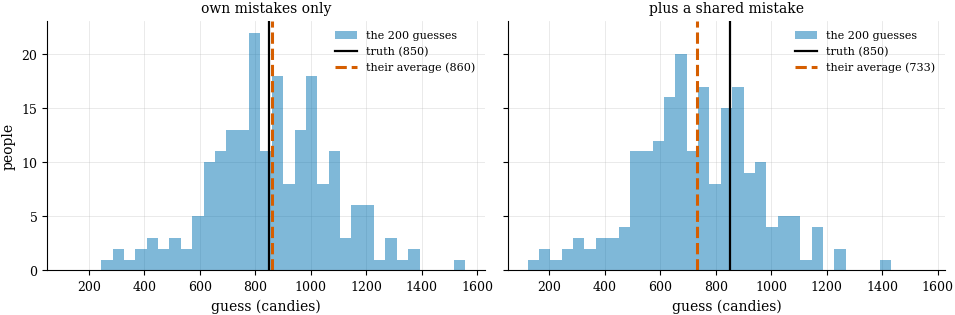

In [2]:
# Galton's ox: the middle guess against the truth, in pounds
middle, ox, q1, q3 = 1207, 1198, 1162, 1236
crowd_err = abs(middle - ox) / ox
typical_err = ((ox - q1) + (q3 - ox)) / 2 / ox          # half of the guesses were closer than this
print(f"Galton: middle guess {middle:,} lb, truth {ox:,} lb -> the crowd is off by {crowd_err:.2%}; "
      f"a typical guess by about {typical_err:.1%} ({typical_err / crowd_err:.1f} times more)\n")

TRUTH = 850                     # candies in the jar
N_PEOPLE = 200                  # <-- CHANGE ME: the size of the crowd
SPREAD = 0.25                   # <-- CHANGE ME: the spread (standard deviation) of a person's own mistake
SHARED = -0.15                  # <-- CHANGE ME: a mistake everybody shares (-0.15 = 15% too low)


def crowd_report(guesses):
    "how far the average is from the truth, how far a typical person is, and how many people it beats"
    avg_off = abs(guesses.mean() - TRUTH)
    person_off = np.abs(guesses - TRUTH)
    return avg_off / TRUTH, np.median(person_off) / TRUTH, np.mean(person_off > avg_off)


rng = np.random.default_rng(3)
own = rng.normal(0, SPREAD, N_PEOPLE)                    # each person's own mistake
independent = np.round(TRUTH * (1 + own))
shared = np.round(TRUTH * (1 + SHARED + own))            # the same people, plus the shared mistake
for name, g in (("own mistakes only", independent), ("plus a shared mistake", shared)):
    avg_err, typical, beats = crowd_report(g)
    print(f"{name:22s} average guess {g.mean():4.0f}, off by {avg_err:5.1%} | a typical person is off "
          f"by {typical:5.1%} | the average beats {beats:.0%} of the people")

# one crowd can be lucky: 1,000 fresh crowds, own mistakes only
rng = np.random.default_rng(123)
many = np.array([crowd_report(np.round(TRUTH * (1 + rng.normal(0, SPREAD, N_PEOPLE))))
                 for _ in range(1000)])
print(f"\nover 1,000 crowds: the average is off by {np.median(many[:, 0]):.1%} (median); a typical "
      f"person by {many[:, 1].mean():.0%}; the average beats {many[:, 2].mean():.0%} of its crowd "
      f"(in the unluckiest crowd, {many[:, 2].min():.0%})")
rng = np.random.default_rng(123)                         # the same 1,000 crowds, plus the shared mistake
many_shared = np.array([crowd_report(np.round(TRUTH * (1 + SHARED + rng.normal(0, SPREAD, N_PEOPLE))))
                        for _ in range(1000)])
print(f"the same 1,000 crowds with the shared mistake: the average is off by "
      f"{np.median(many_shared[:, 0]):.1%} (median)")

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2), sharey=True)
bins = np.linspace(min(independent.min(), shared.min()), max(independent.max(), shared.max()), 36)
for ax, g, title in ((axes[0], independent, "own mistakes only"),
                     (axes[1], shared, "plus a shared mistake")):
    ax.hist(g, bins=bins, color=C0, alpha=0.5, label=f"the {N_PEOPLE} guesses")
    ax.axvline(TRUTH, color="k", lw=1.6, label=f"truth ({TRUTH})")
    ax.axvline(g.mean(), color=C1, lw=2.2, ls="--", label=f"their average ({g.mean():.0f})")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("guess (candies)")
    ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("people")
plt.show()

**What happened.** With only their own mistakes, a typical person misses by 16.7%, yet the average of
the 200 guesses, 860, misses by only 1.2% and beats 96% of the people. The mistakes point in all
directions, so they **cancel** in the average. This crowd was not lucky: over 1,000 crowds the average
misses by 1.2% and beats 96% of its people. (Galton's real crowd: 3.1% for a typical guess, 0.75% for
the crowd.)

With the shared mistake, the average lands at 733, off by 13.8%: the shared 15%, minus the 1.2% by which
this crowd's own mistakes happen to lean high. Averaging still cancels the people's own mistakes (it
still beats 63% of them), but it **cannot remove a mistake that everybody makes**: over the same 1,000
crowds with the shared mistake, the average misses by 15.1% (median).

**Independent errors cancel when you average. Shared errors do not.** Every ensemble in these notebooks
is built on that sentence.

## 2. The members: decision trees

The members of a team can be **any kind of model** (logistic regressions, naive Bayes, neural
networks, ...), but the favorite members are **decision trees**, so here is a quick reminder of what one
is. A tree asks yes/no questions, one feature at a time. Each question cuts a box in two, and each final box
(a **leaf**) gets one answer. Below, scikit-learn grows a tree on ten small points with two features,
$x_1$ and $x_2$, and two classes (circle = 0, square = 1). Then it grows a tree that may ask only **one**
question, a **stump**.

|--- x1 <= 3.50
|   |--- class: 0
|--- x1 >  3.50
|   |--- x2 <= 5.50
|   |   |--- x2 <= 2.50
|   |   |   |--- class: 1
|   |   |--- x2 >  2.50
|   |   |   |--- class: 0
|   |--- x2 >  5.50
|   |   |--- class: 1

the full tree: 4 leaves, training accuracy 100%
the stump:     2 leaves, training accuracy 80%


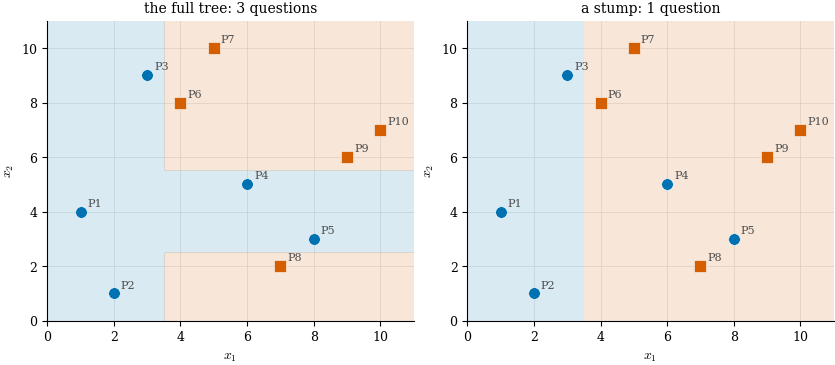

In [3]:
X10, y10 = make_ten_points()
tree10 = DecisionTreeClassifier(random_state=0).fit(X10, y10)
print(export_text(tree10, feature_names=["x1", "x2"]))
print(f"the full tree: {tree10.get_n_leaves()} leaves, training accuracy {tree10.score(X10, y10):.0%}")

stump10 = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X10, y10)   # one question only
print(f"the stump:     {stump10.get_n_leaves()} leaves, training accuracy {stump10.score(X10, y10):.0%}")

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.7))
plot_regions(axes[0], tree10.predict, X10, y10, lim=((0, 11), (0, 11)), s=70, title="the full tree: 3 questions")
plot_regions(axes[1], stump10.predict, X10, y10, lim=((0, 11), (0, 11)), s=70, title="a stump: 1 question")
for ax in axes:
    for i, (a, b) in enumerate(X10):
        ax.annotate(f"P{i + 1}", (a, b), (5, 4), textcoords="offset points", fontsize=8, color="0.3")
plt.show()

The full tree asks three questions ($x_1\le3.5$, then $x_2\le5.5$, then $x_2\le2.5$) and gets all ten
points right. The stump asks only the first one and gets 80% right. A fully grown tree can follow its
training data as closely as it likes; a stump is deliberately simple. Both come back later:
deep trees as members that get averaged, stumps as members that correct each other.

## 3. The problem: one tree is unstable

The **two moons**: 300 points in two interleaving half-moons, with noise, split into 180 training and
120 test points. Below, three trees are grown with the same recipe on three random **resamples** of the
180 training points. A resample draws 180 points from the 180 at random, *with replacement*, so some
points appear twice and others not at all: three slightly different copies of the same data. In the
pictures, filled points are in that tree's resample and hollow points were left out of it.

two moons: 180 training points, 120 test points
tree 1: trained on 111 different points, 19 leaves, test accuracy 0.867
tree 2: trained on 111 different points, 10 leaves, test accuracy 0.858
tree 3: trained on 108 different points, 14 leaves, test accuracy 0.858
the three trees disagree on 18 of the 120 test points (15%)


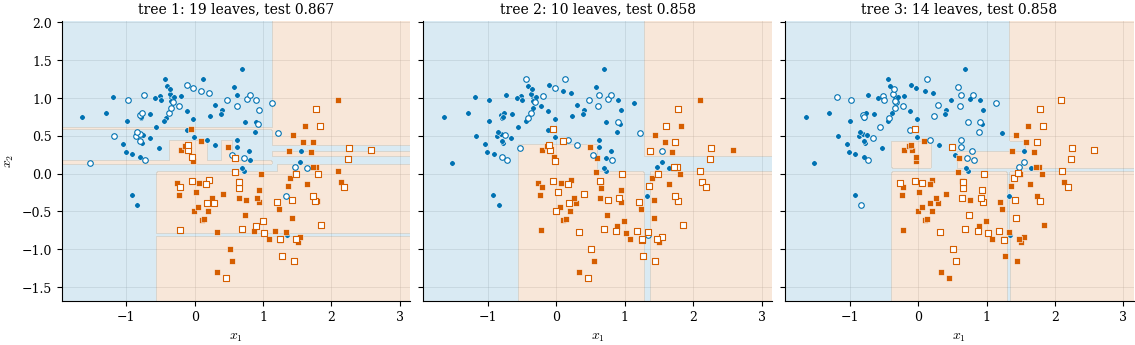

In [4]:
X, y = make_moons(n_samples=300, noise=0.32, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)
print(f"two moons: {len(ytr)} training points, {len(yte)} test points")

rng = np.random.default_rng(3)                  # <-- CHANGE ME: other resamples, other trees
trees, samples = [], []
for k in range(3):
    idx = rng.integers(0, len(ytr), len(ytr))   # 180 draws, with replacement
    tree = DecisionTreeClassifier(random_state=0).fit(Xtr[idx], ytr[idx])
    trees.append(tree)
    samples.append(idx)
    print(f"tree {k + 1}: trained on {len(np.unique(idx))} different points, "
          f"{tree.get_n_leaves():2d} leaves, test accuracy {tree.score(Xte, yte):.3f}")

preds = np.array([t.predict(Xte) for t in trees])
disagree = preds.min(axis=0) != preds.max(axis=0)          # the three trees do not all agree
print(f"the three trees disagree on {disagree.sum()} of the {len(yte)} test points "
      f"({disagree.mean():.0%})")

lim = ((X[:, 0].min() - 0.3, X[:, 0].max() + 0.3), (X[:, 1].min() - 0.3, X[:, 1].max() + 0.3))
fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.5), sharey=True)
for k, (ax, tree, idx) in enumerate(zip(axes, trees, samples)):
    seen = np.isin(np.arange(len(ytr)), idx)                # in this tree's resample: filled
    plot_regions(ax, tree.predict, Xtr[seen], ytr[seen], lim,
                 title=f"tree {k + 1}: {tree.get_n_leaves()} leaves, test {tree.score(Xte, yte):.3f}")
    for lab, c, mk in ((0, C0, "o"), (1, C1, "s")):         # left out of it: hollow
        sel = ~seen & (ytr == lab)
        ax.scatter(*Xtr[sel].T, s=16, marker=mk, facecolor="white", edgecolor=c, linewidth=0.8)
    if k:
        ax.set_ylabel("")
plt.show()

Same recipe, nearly the same data, three very different trees: 19, 10 and 14 leaves, with boundaries
that zigzag in different places. Their test accuracy is about the same (0.858 to 0.867), yet they
disagree on 18 of the 120 test points. A fully grown tree is **jumpy**: a small change in the data moves
its boundary a lot.

Think of each tree as a dart thrown at the truth. Deep trees land around the bull's-eye *on average*
(low **bias**) but scatter widely (high **variance**). A stump is the opposite: it barely moves (low
variance), but it sits off-center (high bias). Can a team tighten the scatter? Sections 4 and 5 answer
with votes, section 6 with averages.

## 4. A tiny experiment: three voters, ten examples

Three voters (think: three classifiers) answer ten yes/no examples, and each is right on 7 of the 10
(70%). The team follows the **majority**: on each example it gives the answer of at least two of the
three. Below, the same kind of voters form three teams that differ only in **where** their mistakes fall
(`X` = a wrong answer, `.` = a right one).

In [5]:
TEAMS = {                                    # <-- CHANGE ME: move the mistakes around
    "mistakes never on the same example": ({8, 9, 10}, {5, 6, 7}, {2, 3, 4}),
    "the same three mistakes":            ({8, 9, 10}, {8, 9, 10}, {8, 9, 10}),
    "mistakes overlapping in pairs":      ({1, 2, 4}, {1, 3, 4}, {2, 3, 10}),
}


def show_votes(name, wrong_sets, n=10):
    "print the right (.) / wrong (X) grid of the voters and of their majority vote"
    right = np.array([[k not in wrong for k in range(1, n + 1)] for wrong in wrong_sets])
    team = right.sum(axis=0) > len(wrong_sets) / 2   # right where most of the voters are right
    marks = lambda row: "".join(f"{'.' if r else 'X':>3s}" for r in row)
    print(name)
    print(f"  {'example':15s}" + "".join(f"{k:>3d}" for k in range(1, n + 1)))
    for v, row in enumerate(right):
        print(f"  {f'voter {v + 1} ({row.sum()}/{n})':15s}" + marks(row))
    print(f"  {f'TEAM    ({team.sum()}/{n})':15s}" + marks(team) + "\n")


for name, wrong in TEAMS.items():
    show_votes(name, wrong)

mistakes never on the same example
  example          1  2  3  4  5  6  7  8  9 10
  voter 1 (7/10)   .  .  .  .  .  .  .  X  X  X
  voter 2 (7/10)   .  .  .  .  X  X  X  .  .  .
  voter 3 (7/10)   .  X  X  X  .  .  .  .  .  .
  TEAM    (10/10)  .  .  .  .  .  .  .  .  .  .

the same three mistakes
  example          1  2  3  4  5  6  7  8  9 10
  voter 1 (7/10)   .  .  .  .  .  .  .  X  X  X
  voter 2 (7/10)   .  .  .  .  .  .  .  X  X  X
  voter 3 (7/10)   .  .  .  .  .  .  .  X  X  X
  TEAM    (7/10)   .  .  .  .  .  .  .  X  X  X

mistakes overlapping in pairs
  example          1  2  3  4  5  6  7  8  9 10
  voter 1 (7/10)   X  X  .  X  .  .  .  .  .  .
  voter 2 (7/10)   X  .  X  X  .  .  .  .  .  .
  voter 3 (7/10)   .  X  X  .  .  .  .  .  .  X
  TEAM    (6/10)   X  X  X  X  .  .  .  .  .  .



Same voters, 70% each, three teams: 10/10, 7/10 and 6/10. In the first team every mistake is outvoted by
the other two voters. In the second the mistakes always coincide, so the team is just one voter. In the
third they overlap two at a time on four examples, and the team is **worse** than every one of its
members.

What decides is **where** the mistakes fall: a team helps when its members' mistakes **rarely land on the
same examples**.

## 5. Counting it: voters who make independent mistakes

Real voters do not choose where to be wrong. Suppose each of three voters is right with probability 0.7,
**on their own** (independently, like three separate coin flips). There are $2\times2\times2=8$ possible
outcomes; the cell lists them with their probabilities and adds up those where the majority is right.
Then it does the same sum for $B$ voters (the binomial formula, with `math.comb`), and checks it with a
simulation.

**Predict first:** is the majority of the three right more often than 70%, or less?

voters (1, 1, 1): probability 0.343   <- majority right
voters (1, 1, 0): probability 0.147   <- majority right
voters (1, 0, 1): probability 0.147   <- majority right
voters (1, 0, 0): probability 0.063
voters (0, 1, 1): probability 0.147   <- majority right
voters (0, 1, 0): probability 0.063
voters (0, 0, 1): probability 0.063
voters (0, 0, 0): probability 0.027
all three right 0.343 + exactly two right 3 x 0.147 = 0.441  ->  P(majority right) = 0.784

each voter right 70% -> majority right: 1 voters 0.700, 3 voters 0.784, 25 voters 0.983
each voter right 40% -> majority right: 1 voters 0.400, 3 voters 0.352, 25 voters 0.154
simulation, 25 voters right 70% of the time: majority right in 0.982 of 100,000 committees


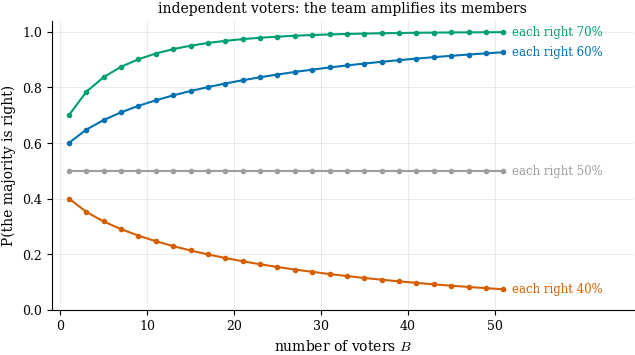

In [6]:
p = 0.7                                   # <-- CHANGE ME: how often one voter is right
total = 0.0
for outcome in itertools.product((1, 0), repeat=3):       # 1 = right, 0 = wrong
    prob = math.prod(p if r else 1 - p for r in outcome)
    majority = sum(outcome) >= 2
    total += prob * majority
    print(f"voters {outcome}: probability {prob:.3f}" + ("   <- majority right" if majority else ""))
print(f"all three right {p ** 3:.3f} + exactly two right 3 x {p ** 2 * (1 - p):.3f} = {3 * p ** 2 * (1 - p):.3f}"
      f"  ->  P(majority right) = {total:.3f}\n")


def p_majority(p, B):
    "P(the majority of B independent voters is right), each right with probability p (B odd)"
    return sum(math.comb(B, k) * p ** k * (1 - p) ** (B - k) for k in range(B // 2 + 1, B + 1))


for p_ in (p, 0.4):
    print(f"each voter right {p_:.0%} -> majority right: "
          + ", ".join(f"{B} voters {p_majority(p_, B):.3f}" for B in (1, 3, 25)))

rng = np.random.default_rng(0)
committees = rng.random((100_000, 25)) < p               # 100,000 simulated committees of 25 voters
print(f"simulation, 25 voters right {p:.0%} of the time: majority right in "
      f"{np.mean(committees.sum(axis=1) >= 13):.3f} of 100,000 committees")

Bs = np.arange(1, 52, 2)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for p_, c in ((0.7, CG), (0.6, C0), (0.5, CX), (0.4, C1)):
    curve = [p_majority(p_, B) for B in Bs]
    ax.plot(Bs, curve, "o-", ms=3, color=c)
    ax.annotate(f"each right {p_:.0%}", (Bs[-1], curve[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=c)
ax.set_xlim(-1, Bs[-1] + 15)
ax.set_xticks(range(0, 51, 10))
ax.set_xlabel("number of voters $B$")
ax.set_ylabel("P(the majority is right)")
ax.set_ylim(0, 1.04)
ax.set_title("independent voters: the team amplifies its members", fontsize=10)
plt.show()

Three independent voters at 70% give a majority that is right with probability 0.343 + 0.441 = 0.784,
better than any one of them; 25 such voters give 0.983, and the simulation agrees. But voters who are
right only 40% of the time get **worse** together: 0.352 for 3, and 0.154 for 25. In the plot, each
curve moves away from 0.5 as the team grows, in the direction of its members (coin-flip voters, right
50% of the time, stay at 0.5).

A team beats its members when (1) each member is **better than a coin flip**, and (2) the members make
their mistakes **independently**. The second team of section 4 broke condition (2) completely.

## 6. Averaging numbers: the noise cancels (and what it cannot fix)

For numbers, a team **averages**. Our data: the **noisy wave**, 90 points with $x$ between $-3$ and $3$
and $y=\sin(1.4x)+0.3x$ plus random noise. The experiment: draw a fresh noisy dataset, fit a model, and
record its prediction at one point, $x=1$. Repeat 300 times and look at how much those predictions
**spread** (their standard deviation) and where they **center** (their mean, compared with the truth).
We try two kinds of member:

* a **deep tree**, fully grown, which follows every noisy point, and
* a **stump**, one question, which draws a single step;

and three kinds of team: one model alone; the **average of 10 models, each trained on its own fresh
dataset**; and, for comparison, 10 deep trees all trained on **one** dataset.

**Predict first:** averaging 10 stumps will make their predictions less spread out. Will it also bring
them closer to the truth?

In [7]:
x0 = np.array([[1.0]])                   # the point where we watch the predictions
truth0 = noisy_wave_truth(1.0)
R, B = 300, 10                           # <-- CHANGE ME: repetitions, and the team size B
LABELS = {"deep_one": "deep tree, one", "deep_avg": f"deep tree, average of {B}",
          "deep_same": f"deep tree, {B} trees on one dataset",
          "stump_one": "stump, one", "stump_avg": f"stump, average of {B}"}
res = {key: [] for key in LABELS}

rng = np.random.default_rng(11)
for r in range(R):
    deep, stump = [], []
    for b in range(B):                   # B fresh training sets, one per member
        x, y = sample_noisy_wave(rng)
        deep.append(DecisionTreeRegressor(random_state=0).fit(x[:, None], y).predict(x0)[0])
        stump.append(DecisionTreeRegressor(max_depth=1, random_state=0).fit(x[:, None], y).predict(x0)[0])
    res["deep_one"].append(deep[0])
    res["deep_avg"].append(np.mean(deep))
    res["stump_one"].append(stump[0])
    res["stump_avg"].append(np.mean(stump))
    x, y = sample_noisy_wave(rng)        # ONE more dataset, and B deep trees (B seeds) all trained on it
    same = [DecisionTreeRegressor(random_state=b).fit(x[:, None], y).predict(x0)[0] for b in range(B)]
    res["deep_same"].append(np.mean(same))

print(f"truth at x = 1: {truth0:.3f}\n")
print(f"{'':36s}{'center':>8s}{'offset':>9s}{'spread':>9s}")
for key, label in LABELS.items():
    v = np.array(res[key])
    print(f"{label:36s}{v.mean():8.3f}{v.mean() - truth0:+9.3f}{v.std():9.3f}")
print(f"\nspread of one / spread of the average: "
      f"deep trees {np.std(res['deep_one']) / np.std(res['deep_avg']):.2f}, "
      f"stumps {np.std(res['stump_one']) / np.std(res['stump_avg']):.2f}   (square root of B = {math.sqrt(B):.2f})")

truth at x = 1: 1.285

                                      center   offset   spread
deep tree, one                         1.301   +0.015    0.300
deep tree, average of 10               1.290   +0.004    0.094
deep tree, 10 trees on one dataset     1.274   -0.012    0.281
stump, one                             0.818   -0.467    0.091
stump, average of 10                   0.809   -0.476    0.031

spread of one / spread of the average: deep trees 3.18, stumps 2.98   (square root of B = 3.16)


The same numbers in pictures. Left: one training set, with a deep tree (it follows every noisy point)
and a stump (a single step); the dotted line marks $x=1$. Middle and right: the 300 predictions at
$x=1$ of one model (gray) and of the average of 10 models, each with its own data (green).

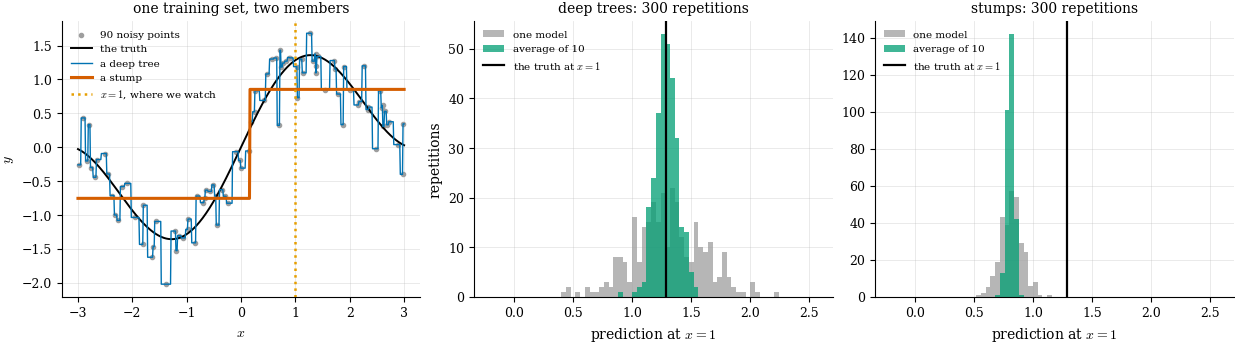

In [8]:
xs, ys = make_noisy_wave()               # one training set, to see what the two members look like
grid = np.linspace(-3, 3, 600)
fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.5))
ax = axes[0]
ax.scatter(xs, ys, s=9, color=CX, label="90 noisy points")
ax.plot(grid, noisy_wave_truth(grid), color="k", lw=1.4, label="the truth")
ax.plot(grid, DecisionTreeRegressor(random_state=0).fit(xs[:, None], ys).predict(grid[:, None]),
        color=C0, lw=1.0, label="a deep tree")
ax.plot(grid, DecisionTreeRegressor(max_depth=1, random_state=0).fit(xs[:, None], ys).predict(grid[:, None]),
        color=C1, lw=2.2, label="a stump")
ax.axvline(1.0, color=CN, ls=":", lw=1.8, label="$x=1$, where we watch")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
ax.set_title("one training set, two members", fontsize=10)
ax.legend(fontsize=7.5, loc="upper left")
bins = np.arange(-0.2, 2.6, 0.04)
for ax, kind, title in ((axes[1], "deep", "deep trees"), (axes[2], "stump", "stumps")):
    ax.hist(res[f"{kind}_one"], bins=bins, color=CX, alpha=0.75, label="one model")
    ax.hist(res[f"{kind}_avg"], bins=bins, color=CG, alpha=0.75, label=f"average of {B}")
    ax.axvline(truth0, color="k", lw=1.6, label="the truth at $x=1$")
    ax.set_xlabel("prediction at $x=1$")
    ax.set_title(f"{title}: {R} repetitions", fontsize=10)
    ax.legend(fontsize=7.5, loc="upper left")
axes[1].set_ylabel("repetitions")
plt.show()

**What happened.** One deep tree is right *on average*: its predictions center within 0.015 of the
truth. But they spread widely (0.300). The average of 10 deep trees, each trained on its own data, keeps
the center and shrinks the spread to 0.094, about $0.300/\sqrt{10}$: for $B$ independent members the
spread falls like $1/\sqrt{B}$ (the ratio printed is 3.18, against $\sqrt{10}=3.16$).

The stumps spread little (0.091) but are centered 0.467 **below** the truth: a stump gives the same
answer on the whole right half of the wave, and at $x=1$ that answer is too low. Averaging 10 stumps
shrinks the spread to 0.031 and leaves the offset where it was ($-0.467$ for one stump, $-0.476$ for the
average of 10). **Averaging fixes variance (scatter), not bias (an offset).** Moving an off-center model
takes a different kind of team, whose members **correct** each other: boosting.

And the team without diversity: 10 deep trees trained on the same dataset, even with 10 different seeds,
are 10 identical trees, so the team spreads like one tree (0.281, against 0.300 for one tree: the same,
up to the luck of 300 repetitions). The members must **differ**.

## Recap & exercises

**Recap.**

* **The crowd.** People's own mistakes cancel in the average (1.2% off, against 16.7% for a typical
  person); a mistake they all share does not (13.8% off).
* **Deep trees are jumpy.** Three resamples of the same 180 points gave trees with 19, 10 and 14 leaves
  that disagree on 15% of the test points.
* **Voting.** Three voters at 70% made teams that scored 10/10, 7/10 or 6/10, depending only on where
  their mistakes fell.
* **Counting.** Independent voters better than a coin flip get better together (70% each: 0.784 for 3,
  0.983 for 25); voters worse than a coin flip get worse together (40% each: 0.352, 0.154).
* **Averaging.** It shrinks the spread like $1/\sqrt{B}$ when the members are independent (0.300 to
  0.094), but it cannot move an offset (the stumps stayed about 0.47 too low), and copies of one model
  gain nothing.
* So the members worth averaging are **right on average, jumpy, and different from each other**: deep
  trees, each trained on different data. In practice there is only **one** dataset. How a team of
  different trees is still possible is the next question.

**Exercises.**

1. In &sect;1, set `SHARED = 0`, then `SHARED = -0.30`. Then try `N_PEOPLE = 20` and `N_PEOPLE = 2000`.
   Which error does a bigger crowd shrink: the one that comes from the people's own mistakes, or the
   shared one?
2. In &sect;1, set `SPREAD = 0.5`: every person is twice as bad. How much worse does the average get,
   compared with a typical person? (A few people now guess a negative number of candies: a bell-shaped
   mistake this large is only a rough model of real people.)
3. In &sect;4, three voters at 70% made a team that scored 6/10. Show that no team of three 70% voters on
   ten examples can score less. (Hint: count the wrong answers, 3 per voter. Where is the team wrong?)
   Then edit `TEAMS` to build a team that scores exactly 8/10.
4. In &sect;5, set `p = 0.55`. How many voters does the majority need to be right 90% of the time? (Loop
   over the odd `B` from 1 to 301 with `p_majority`.) What happens with `p = 0.5`?
5. In &sect;6, set `B = 40` (the cell then takes about 25 seconds). Does the spread of the deep-tree
   average follow $0.300/\sqrt{B}$? Does the stumps' offset move? (The stumps' ratio is noisier: one
   stump's spread is measured on only 300 predictions.)
6. **Predict, then explain with &sect;6.** We are about to average 100 copies of a model, each trained
   on a slightly different version of the same data. Which improves more: a deep decision tree, or a
   linear regression (a straight line)? Write down your answer and the reason.
7. **Write it yourself: voters who copy.** Simulate 100,000 committees of 25 voters, each right with
   probability 0.7, but in each committee, with probability 0.5, every voter simply copies voter 1
   (otherwise they all vote on their own). How often is the majority right? Compare with 0.983 and with
   0.7. Which line of the recap does this illustrate?